# Causal Streaming `r_norm` — does the drift fix survive going real-time?

Acausal `r_norm` (whole-session z-score + symmetric smooth) looks into the future and can't run on a device.
This notebook compares it against strictly **causal** variants on the same LINK sessions.

## 0 · Setup

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# make neurosignal importable without reinstalling
ROOT = Path.cwd()
PKG = ROOT / "02_package" / "src"
if PKG.exists() and str(PKG) not in sys.path:
    sys.path.insert(0, str(PKG))

from neurosignal.io.loaders import list_link_nwb_paths, load_link_sessions
from neurosignal.gold.drift import (
    qc_sbp_sessions, filter_sessions_by_bad_dates,
    normalize_sessions_sbp_gold, compute_pairwise_r2_matrix, _make_xy,
    compute_day_offsets,
)
from neurosignal.gold.streaming import (
    causal_zscore_ewma, causal_zscore_window, causal_smooth_ewma,
    normalize_sessions_sbp_gold_causal, EwmaNormalizer, stream_session,
)
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from neurosignal.viz import init_figure_export, save_figure, get_figure_registry
from neurosignal.io.loaders import get_repo_root

ALPHA = 0.01          # EWMA update rate
ALPHA_SMOOTH = 0.2    # one-pole smoother
WIN_BINS = 300        # sliding-window comparison
WARMUP = 300          # bins excluded as warm-up
OUT_DIR = get_repo_root() / "04_output"
NOTEBOOK_FIG_ID = "05_causal_streaming"

# Larger fonts for all notebook figures
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 16,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
})

init_figure_export(OUT_DIR, notebook_id=NOTEBOOK_FIG_ID, subdir="figures_supporting", reset=True)
print("setup ok")

setup ok


## 1 · Load + QC sessions (same data as Parts 1–3)

In [2]:
paths = list_link_nwb_paths()
sessions_sbp, sessions_vel, dates = load_link_sessions(paths)
df_qc, bad_dates = qc_sbp_sessions(sessions_sbp, sessions_vel, dates)
sessions_sbp, sessions_vel, dates, _keep = filter_sessions_by_bad_dates(
    sessions_sbp, sessions_vel, dates, bad_dates)
print(f"{len(sessions_sbp)} sessions kept (dropped {len(bad_dates)} QC outliers)")
print("shape of session 0:", sessions_sbp[0].shape)

30 sessions kept (dropped 0 QC outliers)
shape of session 0: (27649, 96)


## 2 · Causality proof — batch == sample-by-sample replay
If these match, the batch implementation provably never looks forward.

In [3]:
X0 = sessions_sbp[0]
z_batch = causal_zscore_ewma(X0, alpha=ALPHA)
norm = EwmaNormalizer(n_channels=X0.shape[1], alpha=ALPHA)
z_replay = np.array([norm.update(x) for x in stream_session(X0)])
print("batch == replay:", np.allclose(z_batch, z_replay))

batch == replay: True


## 3 · Build feature sets
`acausal` (baseline) vs `causal_ewma` vs `causal_window`.

In [4]:
feat = {
    "acausal":       normalize_sessions_sbp_gold(sessions_sbp),
    "causal_ewma":   normalize_sessions_sbp_gold_causal(
                         sessions_sbp, alpha=ALPHA, alpha_smooth=ALPHA_SMOOTH, warmup=0),
    "causal_window": [causal_smooth_ewma(causal_zscore_window(s, win_bins=WIN_BINS),
                                         alpha_smooth=ALPHA_SMOOTH) for s in sessions_sbp],
}
for k, v in feat.items():
    print(f"{k:14s} -> {len(v)} sessions, e.g. {v[0].shape}")

acausal        -> 30 sessions, e.g. (27649, 96)
causal_ewma    -> 30 sessions, e.g. (27649, 96)
causal_window  -> 30 sessions, e.g. (27649, 96)


## 4 · Cost of causality — pairwise cross-session R²
Mean off-diagonal R² = how well a decoder trained on one day transfers to another.

Every feature set is scored on bins after the first `WARMUP` = 300 bins (6 s) of each session, where the causal statistics are still converging. All sets are trimmed the same way, so the comparison stays like-for-like.

In [5]:
def mean_off_diag(R):
    M = R.copy(); np.fill_diagonal(M, np.nan)
    return np.nanmean(M)

# Score only bins after the warm-up; the features themselves are still computed on the full session.
trim = lambda sessions: [s[WARMUP:] for s in sessions]
vel_scored = trim(sessions_vel)
feat_scored = {name: trim(fs) for name, fs in feat.items()}

results = {}
for name, fs in feat_scored.items():
    R = compute_pairwise_r2_matrix(fs, vel_scored)
    results[name] = (R, mean_off_diag(R))
    print(f"{name:14s} mean off-diagonal R² = {results[name][1]: .4f}")

base = results["acausal"][1]
print("\nCost of causality (Δ vs acausal):")
for name in ("causal_ewma", "causal_window"):
    print(f"  {name:14s} ΔR² = {results[name][1]-base:+.4f}")

# Sanity check: are EWMA and window genuinely different features, or the same signal twice?
R_e, R_w = results["causal_ewma"][0], results["causal_window"][0]
r_feat = np.corrcoef(feat_scored["causal_ewma"][0].ravel(), feat_scored["causal_window"][0].ravel())[0, 1]
print(f"\nmean off-diag, 6 d.p.: ewma {results['causal_ewma'][1]:.6f} · window {results['causal_window'][1]:.6f}")
print(f"max |R_ewma − R_window| over all session pairs = {np.nanmax(np.abs(R_e - R_w)):.4f}")
print(f"feature correlation, session 0 (ewma vs window) = {r_feat:.3f}")

acausal        mean off-diagonal R² =  0.0545


causal_ewma    mean off-diagonal R² =  0.0560


causal_window  mean off-diagonal R² =  0.0512

Cost of causality (Δ vs acausal):
  causal_ewma    ΔR² = +0.0015
  causal_window  ΔR² = -0.0032

mean off-diag, 6 d.p.: ewma 0.055990 · window 0.051221
max |R_ewma − R_window| over all session pairs = 0.0591
feature correlation, session 0 (ewma vs window) = 0.986


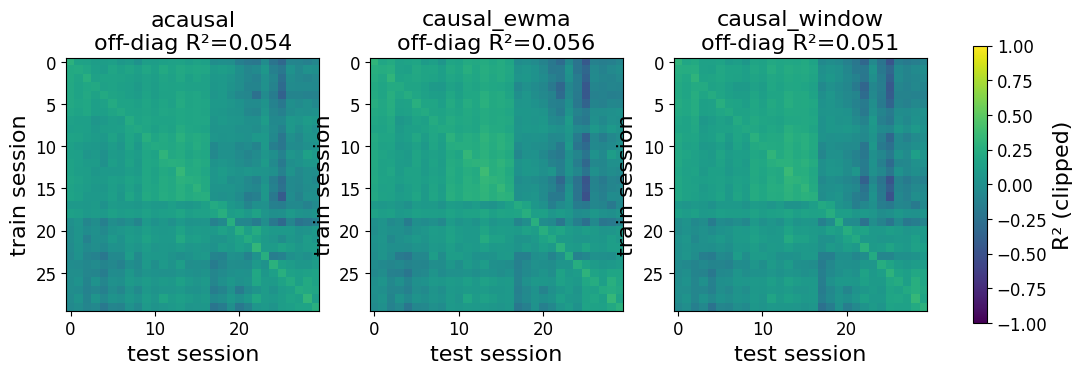

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, name in zip(axes, feat):
    R, m = results[name]
    im = ax.imshow(np.clip(R, -1, 1), vmin=-1, vmax=1, cmap="viridis")
    ax.set_title(f"{name}\noff-diag R²={m:.3f}")
    ax.set_xlabel("test session"); ax.set_ylabel("train session")
fig.colorbar(im, ax=axes, fraction=0.025, label="R² (clipped)")
save_figure(fig, "causal_streaming", "pairwise_r2_acausal_vs_causal", role="candidate_supporting")
plt.show()

## 5 · Warm-up transient
Running std needs time to converge to the true (acausal) std. That lag is the per-session warm-up cost.

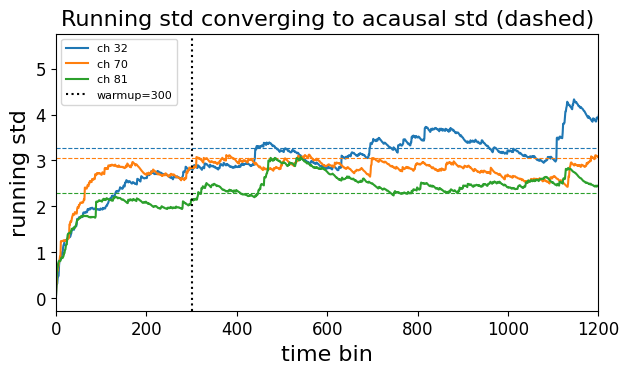

In [7]:
X0 = sessions_sbp[0]
# instrument the running std trajectory for a few active channels
ch = np.argsort(-X0.std(axis=0))[:3]
mu = X0[0].astype(float).copy(); var = np.zeros(X0.shape[1])
run_std = np.empty((X0.shape[0], len(ch)))
for t in range(X0.shape[0]):
    x = X0[t]; mu = (1-ALPHA)*mu + ALPHA*x; var = (1-ALPHA)*var + ALPHA*(x-mu)**2
    run_std[t] = np.sqrt(var)[ch]
final_std = X0.std(axis=0)[ch]

fig, ax = plt.subplots(figsize=(7, 3.6))
for k, c in enumerate(ch):
    ax.plot(run_std[:, k], label=f"ch {c}")
    ax.axhline(final_std[k], ls="--", lw=0.8, color=f"C{k}")
ax.axvline(WARMUP, color="k", ls=":", label=f"warmup={WARMUP}")
ax.set_xlabel("time bin"); ax.set_ylabel("running std"); ax.set_xlim(0, 4*WARMUP)
ax.set_title("Running std converging to acausal std (dashed)"); ax.legend(fontsize=8)
save_figure(fig, "causal_streaming", "warmup_running_std", role="supporting")
plt.show()

## 6 · α sweep — the forgetting-rate knee
Train on session 0, test on all others (cheap), as a function of α. Expect an inverted-U.

alpha=0.001  mean transfer R² =  0.0012


alpha=0.003  mean transfer R² =  0.0197


alpha=0.01   mean transfer R² =  0.0308


alpha=0.03   mean transfer R² =  0.0233


alpha=0.1    mean transfer R² = -0.0176


alpha=0.3    mean transfer R² = -0.0173


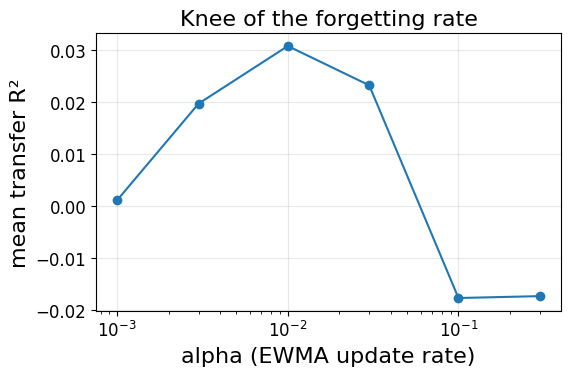

In [8]:
alphas = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
def transfer_r2(feature_sets):
    Xtr, ytr = _make_xy(feature_sets[0][WARMUP:], sessions_vel[0][WARMUP:])
    model = RidgeCV(alphas=(0.1, 1.0, 10.0, 100.0), cv=5).fit(Xtr, ytr)
    scores = []
    for j in range(1, len(feature_sets)):
        Xte, yte = _make_xy(feature_sets[j][WARMUP:], sessions_vel[j][WARMUP:])
        scores.append(r2_score(yte, model.predict(Xte)))
    return np.mean(scores)

curve = []
for a in alphas:
    fs = normalize_sessions_sbp_gold_causal(sessions_sbp, alpha=a, alpha_smooth=ALPHA_SMOOTH)
    curve.append(transfer_r2(fs))
    print(f"alpha={a:<6} mean transfer R² = {curve[-1]: .4f}")

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.semilogx(alphas, curve, "o-")
ax.set_xlabel("alpha (EWMA update rate)"); ax.set_ylabel("mean transfer R²")
ax.set_title("Knee of the forgetting rate"); ax.grid(alpha=0.3)
save_figure(fig, "causal_streaming", "alpha_sweep_knee", role="candidate_supporting")
plt.show()

## 7 · Latency — per-sample update cost
The number a device cares about: time to normalize one incoming sample, extrapolated to 1024 channels.

In [9]:
X0 = sessions_sbp[0]; C = X0.shape[1]
norm = EwmaNormalizer(n_channels=C, alpha=ALPHA)
t0 = time.perf_counter()
for x in stream_session(X0):
    norm.update(x)
dt = time.perf_counter() - t0
per_bin_us = dt / X0.shape[0] * 1e6
print(f"channels: {C}")
print(f"per-bin update: {per_bin_us:.2f} µs  ({per_bin_us/C:.3f} µs/channel)")
print(f"extrapolated to 1024 ch: {per_bin_us/C*1024:.2f} µs/bin")

channels: 96
per-bin update: 5.50 µs  (0.057 µs/channel)
extrapolated to 1024 ch: 58.66 µs/bin


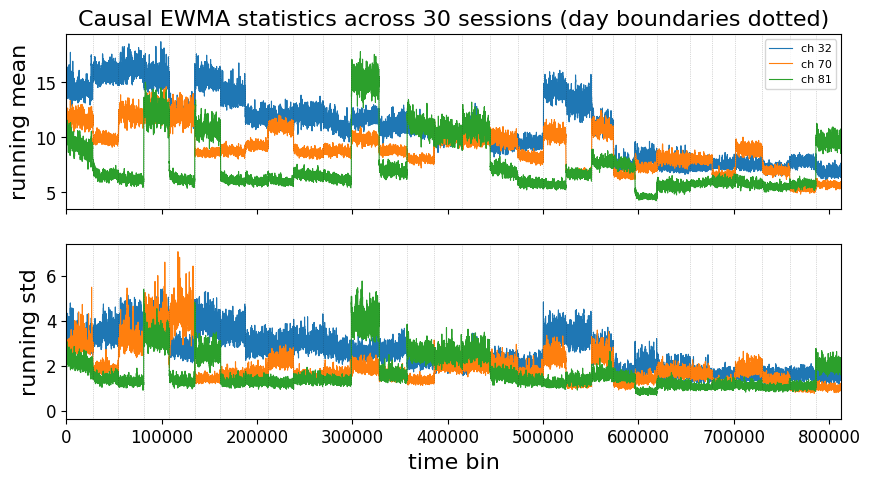

In [10]:
## 8 · Multi-day replay stability
# Stream all 30 sessions chronologically through one causal normalizer and
# verify that running mean/std stay bounded across day boundaries.

all_bins = np.concatenate(sessions_sbp, axis=0)
day_boundaries = np.cumsum([s.shape[0] for s in sessions_sbp])[:-1]
ch = np.argsort(-sessions_sbp[0].std(axis=0))[:3]

norm = EwmaNormalizer(n_channels=all_bins.shape[1], alpha=ALPHA)
run_mu = np.empty((all_bins.shape[0], len(ch)))
run_std = np.empty((all_bins.shape[0], len(ch)))

for t, x in enumerate(stream_session(all_bins)):
    norm.update(x)
    run_mu[t] = norm.mu[ch]
    run_std[t] = np.sqrt(norm.var)[ch]

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for k, c in enumerate(ch):
    axes[0].plot(run_mu[:, k], label=f"ch {c}", lw=0.8)
    axes[1].plot(run_std[:, k], lw=0.8)
for b in day_boundaries:
    axes[0].axvline(b, color="k", ls=":", alpha=0.3, lw=0.5)
    axes[1].axvline(b, color="k", ls=":", alpha=0.3, lw=0.5)
axes[0].set_ylabel("running mean")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].set_ylabel("running std")
axes[1].set_xlabel("time bin")
axes[0].set_title("Causal EWMA statistics across 30 sessions (day boundaries dotted)")
axes[1].set_xlim(0, len(all_bins))
save_figure(fig, "causal_streaming", "multi_day_replay_stability", role="supporting")
plt.show()

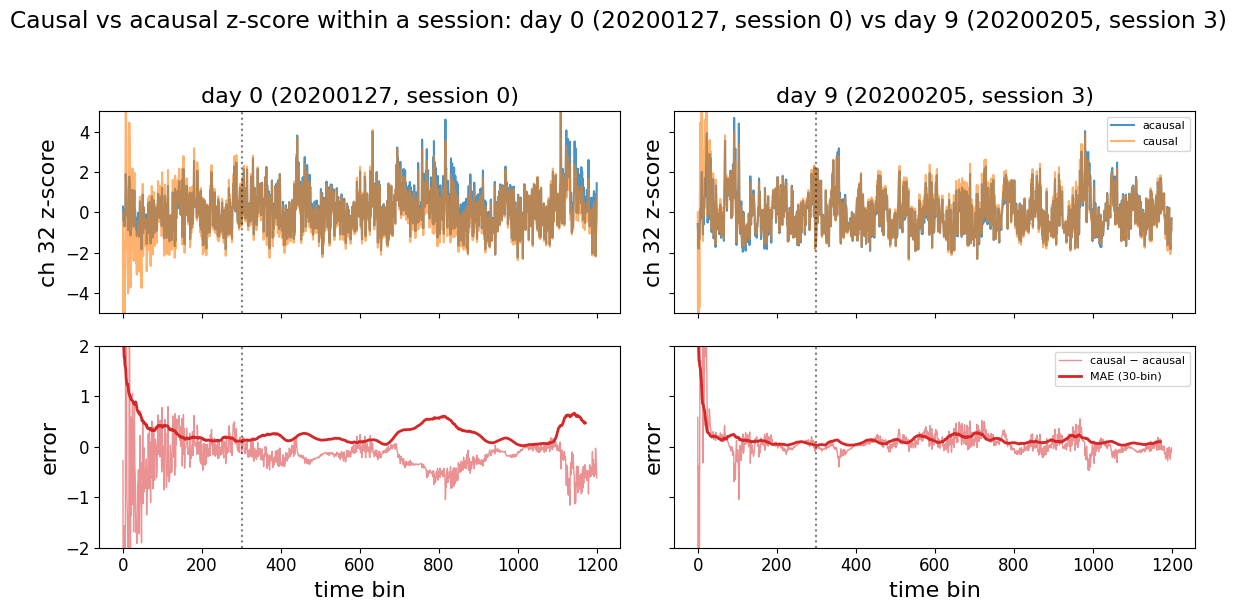

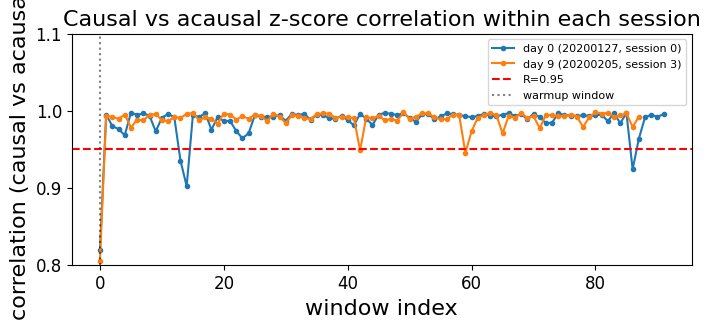

In [11]:
## 9 · Causal vs acausal z-score overlay — two sessions
# First 4×warmup bins of one channel in two sessions. Causal state resets every session,
# so this shows within-session agreement after warm-up only; it says nothing about cross-day decay.

ch = int(np.argsort(-sessions_sbp[0].std(axis=0))[0])  # single most active channel
session_indices = [0, 3]
day_offsets = compute_day_offsets(dates)  # day labels from session dates, never session indices
labels = [f"day {int(day_offsets[i])} ({dates[i]}, session {i})" for i in session_indices]

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex="col", sharey="row")
for col, (idx, label) in enumerate(zip(session_indices, labels)):
    X = sessions_sbp[idx]
    z_acausal = (X - np.nanmean(X, axis=0)) / np.nanstd(X, axis=0)
    z_acausal = np.nan_to_num(z_acausal, nan=0.0, posinf=0.0, neginf=0.0)
    z_causal = causal_zscore_ewma(X, alpha=ALPHA)

    t = np.arange(4 * WARMUP)
    axes[0, col].plot(t, z_acausal[:4*WARMUP, ch], label="acausal", color="C0", alpha=0.8, lw=1.5)
    axes[0, col].plot(t, z_causal[:4*WARMUP, ch], label="causal", color="C1", alpha=0.6, lw=1.5)
    axes[0, col].axvline(WARMUP, color="k", ls=":", alpha=0.5)
    axes[0, col].set_title(label)
    axes[0, col].set_ylabel(f"ch {ch} z-score")
    if col == 1:
        axes[0, col].legend(fontsize=8, loc="upper right")

    error = z_causal[:4*WARMUP, ch] - z_acausal[:4*WARMUP, ch]
    axes[1, col].plot(t, error, color="C3", alpha=0.5, lw=1.0, label="causal − acausal")
    mae = np.convolve(np.abs(error), np.ones(30)/30, mode="valid")
    axes[1, col].plot(t[:len(mae)], mae, color="C3", lw=2.0, label="MAE (30-bin)")
    axes[1, col].axvline(WARMUP, color="k", ls=":", alpha=0.5)
    axes[1, col].set_ylabel("error")
    axes[1, col].set_xlabel("time bin")
    if col == 1:
        axes[1, col].legend(fontsize=8, loc="upper right")

axes[0, 0].set_ylim(-5, 5)
axes[1, 0].set_ylim(-2, 2)
fig.suptitle(f"Causal vs acausal z-score within a session: {labels[0]} vs {labels[1]}", y=1.02)
plt.tight_layout()
save_figure(fig, "causal_streaming", "causal_acausal_two_sessions", role="supporting")
plt.show()

# Rolling correlation comparison
fig, ax = plt.subplots(figsize=(8, 3))
for idx, label in zip(session_indices, labels):
    X = sessions_sbp[idx]
    z_acausal = (X - np.nanmean(X, axis=0)) / np.nanstd(X, axis=0)
    z_acausal = np.nan_to_num(z_acausal, nan=0.0, posinf=0.0, neginf=0.0)
    z_causal = causal_zscore_ewma(X, alpha=ALPHA)
    window = WARMUP
    slide_corr = []
    for start in range(0, X.shape[0] - window, window):
        end = start + window
        corr = np.corrcoef(z_causal[start:end, ch], z_acausal[start:end, ch])[0, 1]
        slide_corr.append(corr)
    ax.plot(slide_corr, "o-", markersize=3, label=label)
ax.axhline(0.95, color="r", ls="--", label="R=0.95")
ax.axvline(0, color="k", ls=":", alpha=0.5, label="warmup window")
ax.set_xlabel("window index")
ax.set_ylabel("correlation (causal vs acausal)")
ax.set_title("Causal vs acausal z-score correlation within each session")
ax.set_ylim(0.8, 1.1)
ax.legend(fontsize=8)
save_figure(fig, "causal_streaming", "causal_acausal_corr_two_sessions", role="supporting")
plt.show()